# MovieLens ile Graf Tabanlı Film Öneri Sistemi
**Araştırma sorusu.** İki parçalı kullanıcı–film grafındaki ortak komşular, gelecekte yüksek puan verilen filmleri ilk 10 öneride bulmaya yardımcı oluyor mu?

**Çalıştırma.** `ratings.csv` ve `movies.csv` dosyalarını notebook ile aynı klasöre veya oradaki `ml-latest-small` klasörüne koyup tüm hücreleri sırayla çalıştır. Veri kaynağı [GroupLens MovieLens Latest Small](https://grouplens.org/datasets/movielens/latest/).

In [1]:
import csv
from collections import Counter, defaultdict, deque
from datetime import datetime, timezone
from hashlib import sha256
from html import escape
from pathlib import Path
from xml.etree import ElementTree as ET

from IPython.display import HTML, SVG, display


def read_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as file:
        return list(csv.DictReader(file))


def show_table(headers, rows):
    head = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


def write_csv(path, headers, rows):
    with Path(path).open("w", encoding="utf-8-sig", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(headers)
        writer.writerows(rows)


data_dir = Path(".") if Path("ratings.csv").is_file() else Path("ml-latest-small")
ratings_file = data_dir / "ratings.csv"
ratings = [
    (int(row["userId"]), int(row["movieId"]), float(row["rating"]), int(row["timestamp"]))
    for row in read_csv(ratings_file)
]
movies = read_csv(data_dir / "movies.csv")
titles = {int(row["movieId"]): row["title"] for row in movies}
assert len(titles) == len(movies)
assert len({(u, m) for u, m, _, _ in ratings}) == len(ratings)
assert all(m in titles and 0.5 <= r <= 5 for _, m, r, _ in ratings)
all_users = sorted({u for u, _, _, _ in ratings})

print("ratings.csv SHA-256:", sha256(ratings_file.read_bytes()).hexdigest())
show_table(["Puanlama", "Kullanıcı", "Katalogdaki film"], [(len(ratings), len(all_users), len(titles))])

ratings.csv SHA-256: aa289ca83157595d0df6aea1be6a4ded676ddc4385472e8313a8ed9805352646


Puanlama,Kullanıcı,Katalogdaki film
100836,610,9742


## Puanlamaları zamana göre ayırma
Puanlamaları ortak bir zaman kesimiyle yaklaşık %80 eğitim ve %20 test olarak ayırdık. Kesim anındaki puanlamaların tamamı eğitimde kaldı. Eğitim döneminde puanlanan filmlerden kullanıcının daha önce puanladıklarını çıkararak aday listesini oluşturduk. Testte 4 veya üzeri puan verilen filmleri beğeni saydık.

Yöntem karşılaştırmasına eğitim geçmişi olan ve testte en az bir aday filmi beğenen kullanıcılar dahil edildi. Aşağıdaki kapsam tablosunda, hem yeni kullanıcıya hem yeni filme ait beğeniler yeni kullanıcı satırına dahil edilmiştir.

In [2]:
LIKE = 4.0
K = 10
timestamps = sorted(t for _, _, _, t in ratings)
cutoff = timestamps[int(0.8 * (len(timestamps) - 1))]
train = [row for row in ratings if row[3] <= cutoff]
test = [row for row in ratings if row[3] > cutoff]
assert max(row[3] for row in train) < min(row[3] for row in test)

train_users = {u for u, _, _, _ in train}
train_movies = {m for _, m, _, _ in train}
test_users = {u for u, _, _, _ in test}
test_likes = [(u, m) for u, m, r, _ in test if r >= LIKE]
relevant = defaultdict(set)
new_user_likes = new_movie_likes = 0
for u, m in test_likes:
    if u not in train_users:
        new_user_likes += 1
    elif m not in train_movies:
        new_movie_likes += 1
    else:
        relevant[u].add(m)
eligible = sum(map(len, relevant.values()))
assert eligible + new_user_likes + new_movie_likes == len(test_likes)

print("Zaman kesimi (UTC):", datetime.fromtimestamp(cutoff, timezone.utc).strftime("%d.%m.%Y %H:%M:%S"))
show_table(["Veri grubu", "Puanlama sayısı", "Pay"], [
    ("Eğitim", len(train), f"{len(train) / len(ratings):.1%}"),
    ("Test", len(test), f"{len(test) / len(ratings):.1%}"),
])
show_table(["Kapsam", "Sayı"], [
    ("Test kullanıcıları", len(test_users)),
    ("Eğitim geçmişi olmayan test kullanıcıları", len(test_users - train_users)),
    ("Karşılaştırmaya alınan kullanıcılar", len(relevant)),
    ("Testteki toplam beğeni", len(test_likes)),
    ("Karşılaştırmaya alınan beğeni", eligible),
    ("Eğitim geçmişi olmayan kullanıcılara ait beğeni", new_user_likes),
    ("Eğitim geçmişi olup filmi eğitimde bulunmayan beğeni", new_movie_likes),
])

Zaman kesimi (UTC): 22.03.2016 08:26:11


Veri grubu,Puanlama sayısı,Pay
Eğitim,80669,80.0%
Test,20167,20.0%


Kapsam,Sayı
Test kullanıcıları,116
Eğitim geçmişi olmayan test kullanıcıları,88
Karşılaştırmaya alınan kullanıcılar,28
Testteki toplam beğeni,9325
Karşılaştırmaya alınan beğeni,665
Eğitim geçmişi olmayan kullanıcılara ait beğeni,8360
Eğitim geçmişi olup filmi eğitimde bulunmayan beğeni,300


## İki parçalı eğitim grafı
Kullanıcı ve film düğümlerini yalnızca eğitim puanlamaları birbirine bağlar. Graf yönsüzdür ve kenar ağırlığı puandır. Beğeni komşuluklarını oluştururken yalnızca 4 ve üzeri puanlı kenarları kullanırız. Grafın bağlılık ve yoğunluk ölçümleri ise bütün eğitim kenarlarına dayanır.

Kullanıcılar önce sıralandığında komşuluk matrisi $A=\begin{pmatrix}0&B\\ B^T&0\end{pmatrix}$ biçimindedir. $B$ eğitim puanlarını içerir. Öneride kullanılan ikili beğeni matrisinin elemanları, eğitim puanı en az 4 ise 1, diğer durumlarda 0'dır.

In [3]:
ratings_by_user = defaultdict(dict)
graph = defaultdict(set)
liked_movies = {u: set() for u in train_users}
liking_users = {m: set() for m in train_movies}
for u, m, rating, _ in train:
    ratings_by_user[u][m] = rating
    left, right = ("user", u), ("movie", m)
    graph[left].add(right)
    graph[right].add(left)
    if rating >= LIKE:
        liked_movies[u].add(m)
        liking_users[m].add(u)

assert len(graph) == len(train_users) + len(train_movies)
assert sum(map(len, graph.values())) == 2 * len(train)
unvisited = set(graph)
component_sizes = []
while unvisited:
    start = unvisited.pop()
    queue = deque([start])
    size = 0
    while queue:
        node = queue.popleft()
        size += 1
        for neighbor in graph[node]:
            if neighbor in unvisited:
                unvisited.remove(neighbor)
                queue.append(neighbor)
    component_sizes.append(size)

show_table(["Graf ölçütü", "Değer"], [
    ("Kullanıcı düğümü", len(train_users)),
    ("Film düğümü", len(train_movies)),
    ("Toplam düğüm", len(graph)),
    ("Kenar", len(train)),
    ("İki parçalı yoğunluk", f"{len(train) / (len(train_users) * len(train_movies)):.4%}"),
    ("Ortalama kullanıcı derecesi", f"{len(train) / len(train_users):.2f}"),
    ("Ortalama film derecesi", f"{len(train) / len(train_movies):.2f}"),
    ("Bağlı bileşen (BFS)", len(component_sizes)),
    ("En büyük bileşendeki düğüm", max(component_sizes)),
])

Graf ölçütü,Değer
Kullanıcı düğümü,522
Film düğümü,7867
Toplam düğüm,8389
Kenar,80669
İki parçalı yoğunluk,1.9644%
Ortalama kullanıcı derecesi,154.54
Ortalama film derecesi,10.25
Bağlı bileşen (BFS),1
En büyük bileşendeki düğüm,8389


## Öneri yöntemleri
- **Popülerlik.** Aday filmleri eğitim döneminde aldıkları beğeni sayısına göre sıralarız.
- **Kullanıcı benzerliği.** İki kullanıcının ortak beğendiği filmleri sayarız. Bir aday filmi beğenen her komşu kullanıcının bu sayısını toplayarak filme puan veririz.
- **Film benzerliği.** Kullanıcının daha önce beğendiği her film ile aday filmi birlikte beğenen kullanıcıları sayarız. Bu sayıları toplayarak aday filme puan veririz.

İki kişiselleştirilmiş yöntemde de puan, kullanıcı ile aday film arasındaki üç kenarlı beğeni yollarının sayısıyla aynıdır. Bu yüzden bu puanlarla iki yöntem aynı sırayı üretir. Puan eşitliğinde önce beğeni sayısını, sonra küçük film kimliğini kullanırız. Eğitim geçmişi olmayan kullanıcılara popülerlik listesini veririz.

In [4]:
popularity = {m: len(users) for m, users in liking_users.items()}


def user_scores(user):
    common_films = Counter(
        neighbor
        for movie in liked_movies[user]
        for neighbor in liking_users[movie]
        if neighbor != user
    )
    scores = Counter()
    for neighbor, overlap in common_films.items():
        for candidate in liked_movies[neighbor]:
            scores[candidate] += overlap
    return scores


# Simetrik ortak kullanıcı sayıları film çiftleri için bir kez hesaplanır.
film_neighbors = {}
for movie, users in liking_users.items():
    film_neighbors[movie] = Counter(
        other
        for user in users
        for other in liked_movies[user]
        if other != movie
    )


def film_scores(user):
    scores = Counter()
    for prior in liked_movies[user]:
        scores.update(film_neighbors[prior])
    return scores


def top_10(user, scores):
    seen = ratings_by_user.get(user, {})
    return sorted(
        train_movies.difference(seen),
        key=lambda movie: (-scores.get(movie, 0), -popularity[movie], movie),
    )[:K]


methods = {
    "Popülerlik": lambda user: popularity,
    "Kullanıcı benzerliği": user_scores,
    "Film benzerliği": film_scores,
}
recommendations = {name: {} for name in methods}
for user in all_users:
    baseline = top_10(user, popularity)
    recommendations["Popülerlik"][user] = baseline
    for name in ("Kullanıcı benzerliği", "Film benzerliği"):
        recommendations[name][user] = top_10(user, methods[name](user)) if user in train_users else baseline
    assert recommendations["Kullanıcı benzerliği"][user] == recommendations["Film benzerliği"][user]

for lists in recommendations.values():
    for user, ranking in lists.items():
        assert len(ranking) == len(set(ranking)) == K
        assert set(ranking).issubset(train_movies)
        assert not set(ranking).intersection(ratings_by_user.get(user, {}))
print(f"{len(all_users)} kullanıcı için ilk {K} öneri üretildi.")
print("İki ortak komşu hesabı tüm kullanıcılar için aynı sıralamayı verdi.")

610 kullanıcı için ilk 10 öneri üretildi.
İki ortak komşu hesabı tüm kullanıcılar için aynı sıralamayı verdi.


## Önerilerin değerlendirilmesi
Precision@10, ilk 10 önerideki isabet sayısının 10'a oranıdır. Recall@10, bu isabet sayısının kullanıcının testteki uygun beğeni sayısına oranıdır. Her ölçütü önce kullanıcı düzeyinde hesaplayıp kullanıcılar arasında ortaladık.

Yöntem,Precision@10,Recall@10,Toplam isabet
Popülerlik,8.57%,4.49%,24
Kullanıcı benzerliği,10.71%,5.02%,30
Film benzerliği,10.71%,5.02%,30


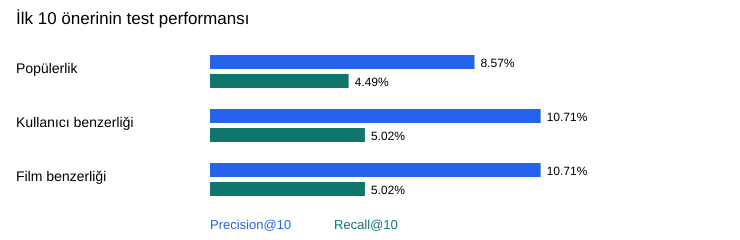

In [5]:
results = []
for name, lists in recommendations.items():
    hits = {u: len(set(lists[u]) & liked) for u, liked in relevant.items()}
    precision = sum(hits.values()) / (K * len(relevant))
    recall = sum(hits[u] / len(relevant[u]) for u in relevant) / len(relevant)
    results.append((name, precision, recall, sum(hits.values())))

show_table(["Yöntem", "Precision@10", "Recall@10", "Toplam isabet"], [
    (name, f"{p:.2%}", f"{r:.2%}", hits) for name, p, r, hits in results
])

def performance_svg(rows):
    left, plot_width = 210, 410
    ymax = max(max(p, r) for _, p, r, _ in rows) * 1.24
    svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="740" height="240" viewBox="0 0 740 240">',
           '<title>İlk 10 önerinin test performansı</title>',
           '<text x="16" y="24" font-family="Arial" font-size="17">İlk 10 önerinin test performansı</text>']
    for index, (name, precision, recall, _) in enumerate(rows):
        y = 55 + index * 54
        svg.append(f'<text x="16" y="{y + 18}" font-family="Arial" font-size="14">{escape(name)}</text>')
        for offset, value, color in ((0, precision, "#2563eb"), (19, recall, "#0f766e")):
            width = value * plot_width / ymax
            svg.append(f'<rect x="{left}" y="{y + offset}" width="{width:.2f}" height="14" fill="{color}"/>')
            svg.append(f'<text x="{left + width + 6:.2f}" y="{y + offset + 12}" font-family="Arial" font-size="12">{value:.2%}</text>')
    svg.append('<text x="210" y="229" fill="#2563eb" font-family="Arial" font-size="13">Precision@10</text>')
    svg.append('<text x="334" y="229" fill="#0f766e" font-family="Arial" font-size="13">Recall@10</text></svg>')
    return "".join(svg)


chart = performance_svg(results)
display(SVG(data=chart))
Path("yontem_karsilastirmasi_ortak_komsu.svg").write_text(chart, encoding="utf-8")
write_csv("yontem_karsilastirmasi_ortak_komsu.csv",
          ["Yöntem", "Precision@10", "Recall@10", "Toplam isabet"], results)
write_csv("ilk_10_film_onerileri_ortak_komsu.csv",
          ["userId", "Yöntem", "Sıra", "movieId", "Film", "Eğitim geçmişi yok"],
          ((u, name, rank, m, titles[m], u not in train_users)
           for name, lists in recommendations.items()
           for u, ranking in lists.items()
           for rank, m in enumerate(ranking, 1)))

## Bir film neden önerildi
Örnek olarak Kullanıcı 15'in ilk 10 kişiselleştirilmiş önerisi arasından, geçmişte beğendiği bir filmle ortak komşusu bulunan ilk filmi seçiyoruz. Bir ortak kullanıcıyı gösteren bu yol, öneri puanına yapılan katkılardan biridir. Test isabeti bilgisi örneğin yanında ayrıca gösterilir.

Örnek yol: Kullanıcı 15 → Lethal Weapon 2 (1989) → Kullanıcı 42 → Star Wars: Episode IV - A New Hope (1977)
Bu iki filmi beğenen ortak kullanıcı sayısı: 7


Sıra,Film,Öneri puanı,Testte beğenildi
1,Star Wars: Episode IV - A New Hope (1977),51,Evet
2,"Matrix, The (1999)",50,Evet
3,Star Wars: Episode V - The Empire Strikes Back (1980),49,Evet
4,Star Wars: Episode VI - Return of the Jedi (1983),47,Evet
5,Forrest Gump (1994),46,Evet
6,Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),46,Evet
7,"Shawshank Redemption, The (1994)",43,Evet
8,"Godfather, The (1972)",43,Evet
9,Saving Private Ryan (1998),42,Hayır
10,Back to the Future (1985),42,Evet


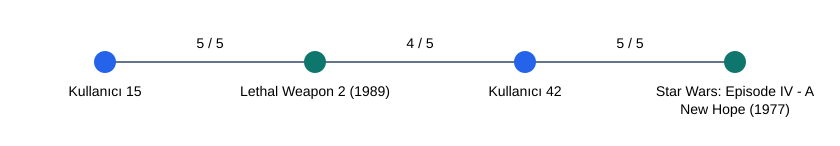

In [6]:
from textwrap import wrap

example_user = 15
example_list = recommendations["Film benzerliği"][example_user]
example_scores = film_scores(example_user)
show_table(["Sıra", "Film", "Öneri puanı", "Testte beğenildi"], [
    (rank, titles[m], score, "Evet" if m in relevant[example_user] else "Hayır")
    for rank, m in enumerate(example_list, 1)
    for score in [example_scores.get(m, 0)]
])

preferred = [(candidate, prior, shared)
             for candidate in example_list
             for prior in sorted(liked_movies[example_user])
             for shared in sorted(liking_users[prior] & liking_users[candidate])]
assert preferred, "Örnek kullanıcının ilk 10 önerisinde beğeni yolu yok."
candidate, prior, shared = preferred[0]
path_nodes = [("user", example_user), ("movie", prior), ("user", shared), ("movie", candidate)]
labels = [f"Kullanıcı {example_user}", titles[prior], f"Kullanıcı {shared}", titles[candidate]]
edge_ratings = [
    ratings_by_user[example_user][prior],
    ratings_by_user[shared][prior],
    ratings_by_user[shared][candidate],
]
assert all(rating >= LIKE for rating in edge_ratings)
print(f"Örnek yol: {' → '.join(labels)}")
print("Bu iki filmi beğenen ortak kullanıcı sayısı:", film_neighbors[candidate][prior])

# Gephi için dört düğümlü açıklama yolunu dışa aktar.
gexf_ns = "http://www.gexf.net/1.2draft"
viz_ns = gexf_ns + "/viz"
ET.register_namespace("", gexf_ns)
ET.register_namespace("viz", viz_ns)
gexf = ET.Element(f"{{{gexf_ns}}}gexf", version="1.2")
subgraph = ET.SubElement(gexf, f"{{{gexf_ns}}}graph", defaultedgetype="undirected", mode="static")
nodes_xml = ET.SubElement(subgraph, f"{{{gexf_ns}}}nodes")
edges_xml = ET.SubElement(subgraph, f"{{{gexf_ns}}}edges")
ids = [f"{kind}_{identifier}" for kind, identifier in path_nodes]
colors = [(37, 99, 235), (13, 148, 136)]
for index, (node_id, label) in enumerate(zip(ids, labels)):
    node = ET.SubElement(nodes_xml, f"{{{gexf_ns}}}node", id=node_id, label=label)
    red, green, blue = colors[index % 2]
    ET.SubElement(node, f"{{{viz_ns}}}color", r=str(red), g=str(green), b=str(blue), a="1.0")
    ET.SubElement(node, f"{{{viz_ns}}}position", x=str(index * 140), y="0", z="0")
    ET.SubElement(node, f"{{{viz_ns}}}size", value="14")
for index, (left, right, rating) in enumerate(zip(ids, ids[1:], edge_ratings)):
    ET.SubElement(edges_xml, f"{{{gexf_ns}}}edge", id=str(index), source=left, target=right,
                  weight=str(rating), label=f"{rating:g} / 5")
ET.ElementTree(gexf).write("film_oneri_yolu_ortak_komsu.gexf", encoding="utf-8", xml_declaration=True)

positions = [105, 315, 525, 735]
elements = ['<svg xmlns="http://www.w3.org/2000/svg" width="840" height="146" viewBox="0 0 840 146">',
            '<title>Film önerisini açıklayan ortak beğeni yolu</title>']
for x, next_x, rating in zip(positions, positions[1:], edge_ratings):
    elements.append(f'<line x1="{x}" x2="{next_x}" y1="62" y2="62" stroke="#64748b" stroke-width="2"/>')
    elements.append(f'<text x="{(x + next_x) // 2}" y="48" text-anchor="middle" font-family="Arial" font-size="14">{rating:g} / 5</text>')
for index, (x, label) in enumerate(zip(positions, labels)):
    color = ("#2563eb", "#0f766e")[index % 2]
    elements.append(f'<circle cx="{x}" cy="62" r="11" fill="{color}"/>')
    for line_index, line in enumerate(wrap(label, width=25)):
        elements.append(f'<text x="{x}" y="{96 + line_index * 18}" text-anchor="middle" font-family="Arial" font-size="14">{escape(line)}</text>')
elements.append("</svg>")
display(SVG(data="".join(elements)))

## Sonuçları yorumlama
İki ortak komşu hesabının aynı sonuç vermesi, aynı üç kenarlı beğeni yollarını farklı sırayla saymalarından kaynaklanır. Popülerlik karşılaştırması bu tek zaman kesimindeki gözlemi gösterir. Performans, eğitim geçmişi bulunan ve testte en az bir uygun beğenisi olan kullanıcılara ve eğitim döneminde puanlanmış filmlere dayanır. Puanlanmamış filmlere ilişkin kullanıcı tercihleri bilinmez.

**Popülerlik** için Precision@10 8.57%, Recall@10 4.49% ve toplam isabet 24 olarak hesaplandı. **Kullanıcı benzerliği** için Precision@10 10.71%, Recall@10 5.02% ve toplam isabet 30 olarak hesaplandı.